<a href="https://colab.research.google.com/github/SantiagoGuz13/Trabajo-/blob/main/Regresi%C3%B3n_Lineal_2222809.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MODELOS  DE REGRESIÓN LINEAL EN PYTHON

In [ ]:
#Cargamos librerias
import io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import linear_model
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.neural_network import MLPRegressor
from scipy.stats import spearmanr, kendalltau
from mpl_toolkits.mplot3d import Axes3D

In [ ]:
#Cargar archivos en google
from google.colab import files
uploaded = files.upload()

Saving SB11_20231.TXT to SB11_20231.TXT


In [ ]:
datos_icfes = pd.read_csv(                      # Leer el archivo como un CSV
    io.BytesIO(uploaded['SB11_20231.TXT']), # Para cargar el archivo y subirlo directamente a google colab
    delimiter='¬',
    engine='python'                             # Se usa engine='python' para evitar la advertencia de Pandas,ya que el motor por defecto ('c') no soporta este tipo de separador
)
datos_icfes.head() #ver las primeras filas del DataFrame

,ESTU_TIPODOCUMENTO,ESTU_NACIONALIDAD,ESTU_GENERO,ESTU_FECHANACIMIENTO,PERIODO,ESTU_CONSECUTIVO,ESTU_ESTUDIANTE,ESTU_PAIS_RESIDE,ESTU_DEPTO_RESIDE,ESTU_COD_RESIDE_DEPTO,...,PUNT_INGLES,PERCENTIL_INGLES,DESEMP_INGLES,PUNT_GLOBAL,PERCENTIL_GLOBAL,ESTU_INSE_INDIVIDUAL,ESTU_NSE_INDIVIDUAL,ESTU_NSE_ESTABLECIMIENTO,PERCENTIL_ESPECIAL_GLOBAL,ESTU_ESTADOINVESTIGACION
0,TI,COLOMBIA,F,04/11/2005,20231,SB11202310019049,ESTUDIANTE,COLOMBIA,CUNDINAMARCA,25,...,87.0,94.0,B+,422,100.0,67.532814,4.0,4,100.0,PUBLICAR
1,TI,COLOMBIA,M,08/04/2007,20231,SB11202310017318,ESTUDIANTE,COLOMBIA,VALLE,76,...,NaN,NaN,NaN,326,NaN,47.223972,2.0,3,100.0,PUBLICAR
2,TI,COLOMBIA,F,26/05/2006,20231,SB11202310030916,ESTUDIANTE,COLOMBIA,VALLE,76,...,NaN,NaN,NaN,186,NaN,67.695519,4.0,3,40.0,PUBLICAR
3,CC,COLOMBIA,F,24/05/2004,20231,SB11202310074169,ESTUDIANTE,COLOMBIA,VALLE,76,...,58.0,43.0,A2,200,12.0,41.863163,2.0,3,58.0,PUBLICAR
4,TI,COLOMBIA,F,04/05/2005,20231,SB11202310044933,ESTUDIANTE,COLOMBIA,VALLE,76,...,69.0,57.0,B1,263,39.0,51.223795,3.0,3,92.0,PUBLICAR


In [ ]:
datos_icfes.info() #Ver el nombre de las columnas

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12704 entries, 0 to 12703
Data columns (total 83 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   ESTU_TIPODOCUMENTO             12704 non-null  object 
 1   ESTU_NACIONALIDAD              12704 non-null  object 
 2   ESTU_GENERO                    12704 non-null  object 
 3   ESTU_FECHANACIMIENTO           12704 non-null  object 
 4   PERIODO                        12704 non-null  int64  
 5   ESTU_CONSECUTIVO               12704 non-null  object 
 6   ESTU_ESTUDIANTE                12704 non-null  object 
 7   ESTU_PAIS_RESIDE               12704 non-null  object 
 8   ESTU_DEPTO_RESIDE              12704 non-null  object 
 9   ESTU_COD_RESIDE_DEPTO          12704 non-null  int64  
 10  ESTU_MCPIO_RESIDE              12704 non-null  object 
 11  ESTU_COD_RESIDE_MCPIO          12704 non-null  int64  
 12  ESTU_PRESENTACIONSABADO        12702 non-null 

In [ ]:
datos_icfes.describe() #Ver las estadísticas de las columnas numérica

,PERIODO,ESTU_COD_RESIDE_DEPTO,ESTU_COD_RESIDE_MCPIO,COLE_CODIGO_ICFES,COLE_COD_DANE_ESTABLECIMIENTO,SEED_CODIGOMEN,COLE_COD_DANE_SEDE,COLE_COD_MCPIO_UBICACION,COLE_COD_DEPTO_UBICACION,ESTU_COD_MCPIO_PRESENTACION,...,PERCENTIL_SOCIALES_CIUDADANAS,DESEMP_SOCIALES_CIUDADANAS,PUNT_INGLES,PERCENTIL_INGLES,PUNT_GLOBAL,PERCENTIL_GLOBAL,ESTU_INSE_INDIVIDUAL,ESTU_NSE_INDIVIDUAL,ESTU_NSE_ESTABLECIMIENTO,PERCENTIL_ESPECIAL_GLOBAL
count,12704.0,12704.000000,12704.000000,12704.000000,1.270400e+04,12704.000000,1.270400e+04,12704.000000,12704.000000,12704.000000,...,12704.00000,12704.000000,12702.000000,12702.000000,12704.000000,12702.000000,11855.000000,11855.000000,12704.000000,11.000000
mean,20231.0,46.861067,46930.803999,137812.243545,3.580633e+11,144.347607,3.580633e+11,47219.970954,47.107761,46800.813996,...,64.00063,2.851464,72.882066,65.866635,316.850362,65.505196,63.008162,3.422522,3.484572,88.000000
std,0.0,31.060190,31076.671884,212074.542023,4.236889e+10,62.767199,4.236889e+10,30787.343950,30.801400,31190.814381,...,24.36030,0.786343,13.992488,22.735517,48.062085,22.852094,7.426674,0.636775,0.531979,19.879638
min,20231.0,5.000000,5001.000000,182.000000,1.765200e+11,5.000000,1.765200e+11,5001.000000,5.000000,5001.000000,...,1.00000,1.000000,26.000000,1.000000,140.000000,1.000000,23.416927,1.000000,2.000000,40.000000
25%,20231.0,11.000000,11001.000000,19497.000000,3.118480e+11,68.000000,3.118480e+11,11001.000000,11.000000,11001.000000,...,47.00000,2.000000,63.000000,50.000000,286.750000,49.000000,58.184055,3.000000,3.000000,92.500000
50%,20231.0,68.000000,68276.000000,55657.000000,3.760010e+11,188.000000,3.760010e+11,68276.000000,68.000000,68001.000000,...,67.00000,3.000000,76.000000,68.000000,323.000000,68.000000,63.989899,3.000000,4.000000,97.000000
75%,20231.0,76.000000,76001.000000,124032.000000,3.760010e+11,188.000000,3.760010e+11,76001.000000,76.000000,76001.000000,...,84.00000,3.000000,82.000000,85.000000,352.000000,85.000000,68.540824,4.000000,4.000000,98.500000
max,20231.0,81.000000,81001.000000,809145.000000,4.768921e+11,272.000000,4.768921e+11,76892.000000,76.000000,81001.000000,...,100.00000,4.000000,100.000000,100.000000,478.000000,100.000000,83.007321,4.000000,4.000000,100.000000


In [ ]:
#Eliminación de valores faltantes en el análisis estadístico
icfes_sin_nan = datos_icfes[(~datos_icfes['ESTU_INSE_INDIVIDUAL'].isna()) &
 (~datos_icfes['PUNT_LECTURA_CRITICA'].isna()) &
 (~datos_icfes['PUNT_MATEMATICAS'].isna()) &
 (~datos_icfes['PUNT_C_NATURALES'].isna()) &
 (~datos_icfes['PUNT_SOCIALES_CIUDADANAS'].isna()) &
 (~datos_icfes['PUNT_INGLES'].isna())]

In [ ]:
#Modelo de Regresión con todas las variables numericas
tabla_regresion = datos_icfes[['ESTU_INSE_INDIVIDUAL','PUNT_LECTURA_CRITICA','PUNT_MATEMATICAS','PUNT_C_NATURALES','PUNT_SOCIALES_CIUDADANAS','PUNT_INGLES']]
tabla_regresion.head(4) #Ver las primeras filas

,ESTU_INSE_INDIVIDUAL,PUNT_LECTURA_CRITICA,PUNT_MATEMATICAS,PUNT_C_NATURALES,PUNT_SOCIALES_CIUDADANAS,PUNT_INGLES
0,67.532814,100,83,77,77,87.0
1,47.223972,67,58,68,68,NaN
2,67.695519,37,42,35,35,NaN
3,41.863163,45,41,41,27,58.0


<Axes: >

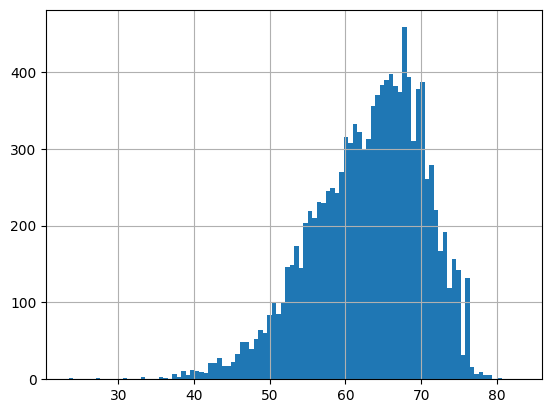

In [ ]:
tabla_regresion[("ESTU_INSE_INDIVIDUAL")].hist(bins=100) #Histograma de la variable dependiente

<Axes: >

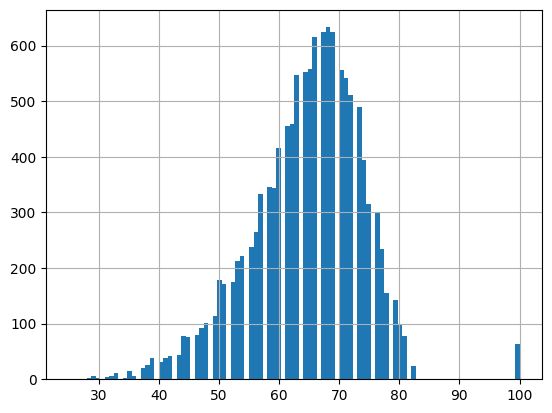

In [ ]:
tabla_regresion[("PUNT_LECTURA_CRITICA")].hist(bins=100) #Histograma de la variable explicativa

<Axes: >

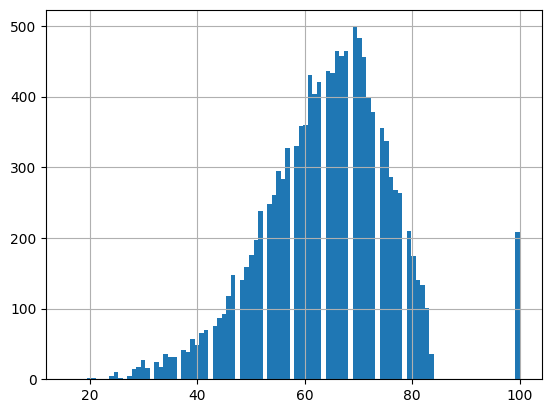

In [ ]:
tabla_regresion[("PUNT_MATEMATICAS")].hist(bins=100) #Histograma de la variable explicativa

<Axes: >

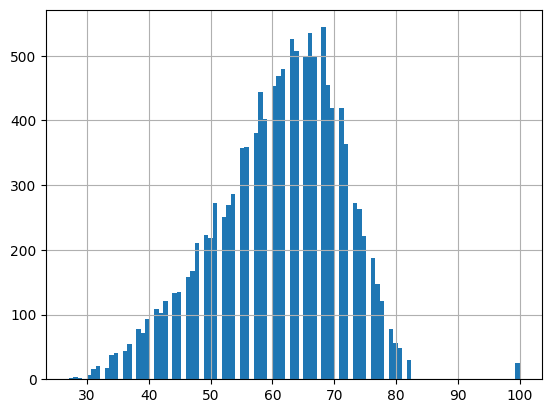

In [ ]:
tabla_regresion[("PUNT_C_NATURALES")].hist(bins=100) #Histograma de la variable explicativa

<Axes: >

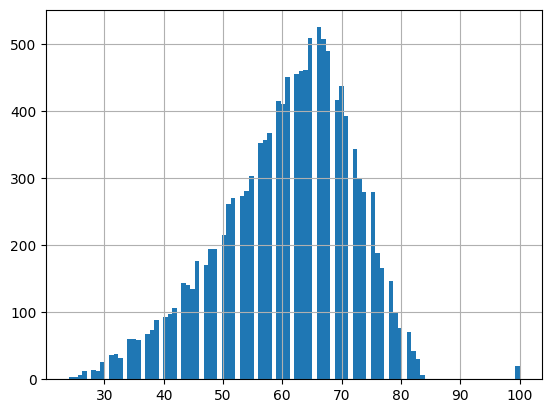

In [ ]:
tabla_regresion[("PUNT_SOCIALES_CIUDADANAS")].hist(bins=100) #Histograma de la variable explicativa

<Axes: >

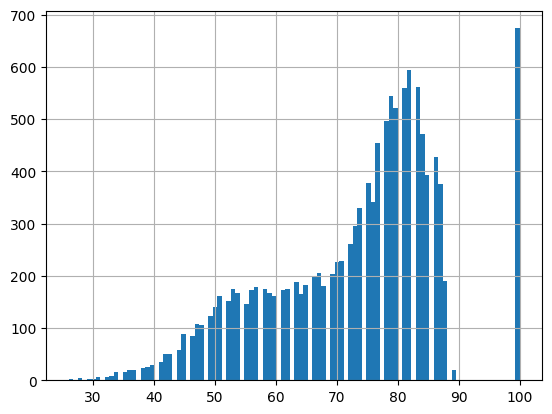

In [ ]:
tabla_regresion[("PUNT_INGLES")].hist(bins=100) #Histograma de la variable explicativa

Histograma de la variable dependiente con las variables explicativas

<Axes: >

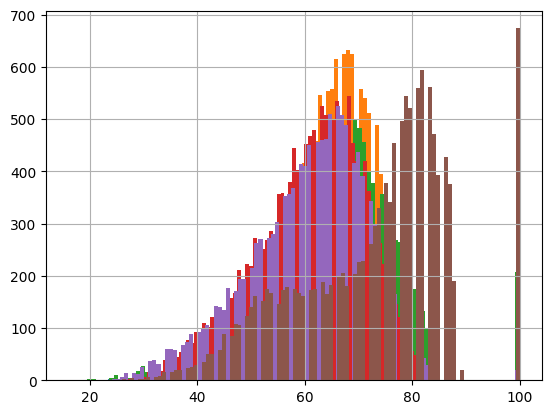

In [ ]:
tabla_regresion[("ESTU_INSE_INDIVIDUAL")].hist(bins=100) #Histograma de la variable dependiente en azul
tabla_regresion[("PUNT_LECTURA_CRITICA")].hist(bins=100) #Histograma de la variable explicativa en naranja
tabla_regresion[("PUNT_MATEMATICAS")].hist(bins=100) #Histograma de la variable explicativa en verde
tabla_regresion[("PUNT_C_NATURALES")].hist(bins=100) #Histograma de la variable explicativa en rojo
tabla_regresion[("PUNT_SOCIALES_CIUDADANAS")].hist(bins=100) #Histograma de la variable explicativa en morado
tabla_regresion[("PUNT_INGLES")].hist(bins=100) #Histograma de la variable explicativa en café

Se observa una barra en $100$ por lo cual vamos a limitar o eliminar datos no representativos para evitar distorciones en el análisis de los datos

In [ ]:
#Selección de datos no representativos para entrenar al modelo de regresión lineal
tabla_regresion1 = tabla_regresion[(tabla_regresion["ESTU_INSE_INDIVIDUAL"]<80) & (tabla_regresion["PUNT_LECTURA_CRITICA"]<90) &
                  (tabla_regresion["PUNT_MATEMATICAS"]<90) & (tabla_regresion["PUNT_C_NATURALES"]<90) & (tabla_regresion["PUNT_SOCIALES_CIUDADANAS"]<90) &
                  (tabla_regresion["PUNT_INGLES"]<90)]

#Visualización de los primeros cinco elementos
tabla_regresion1.head(5)

,ESTU_INSE_INDIVIDUAL,PUNT_LECTURA_CRITICA,PUNT_MATEMATICAS,PUNT_C_NATURALES,PUNT_SOCIALES_CIUDADANAS,PUNT_INGLES
3,41.863163,45,41,41,27,58.0
4,51.223795,53,55,41,56,69.0
5,57.690401,63,38,60,59,45.0
6,39.984838,69,60,59,51,50.0
7,50.613232,57,68,74,61,52.0


# Diagrama de Dispersión

In [ ]:
x = np.array(tabla_regresion1['ESTU_INSE_INDIVIDUAL']).reshape(-1, 1)  #Tipo numpy para una columna
y = tabla_regresion1['PUNT_INGLES']
trainx, testx, trainy, testy = train_test_split(x,y, test_size= 0.2, random_state= 0) #Tomar variables de entrenamiento
modelo_lineal0 = LinearRegression() #Carga de función lineal
regresion0 = modelo_lineal0.fit(trainx,trainy) #Reconocimiento de variable respuesta y explicativas (Datos de entrenamiento)
pred_lineal0 = regresion0.predict(testx)  #Predicción datos de validación

- Diagrama de Dispersión para ESTU_INSE_INDIVIDUAL y PUNT_LECTURA_CRITICA


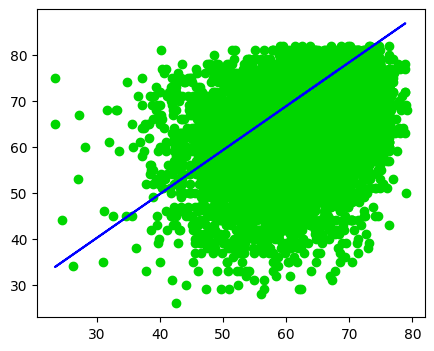

In [ ]:
#Elaboración de diagramas de dispersión, reconocer variables explicativas y no explicativas

plt.figure(figsize=(5,4)) #Genera el tamaño de la figura
plt.scatter(tabla_regresion1["ESTU_INSE_INDIVIDUAL"],tabla_regresion1["PUNT_LECTURA_CRITICA"], c="#00D600") #Diagrama de dispersión, con
                                                                                                            #tabla_regresion1["PUNT_LECTURA_CRITICA"] → valores del eje X (variable explicativa)
                                                                                                            #tabla_regresion1["ESTU_INSE_INDIVIDUAL"] → valores del eje Y (variable respuesta)

plt.plot(testx, pred_lineal0, linestyle = "-", color= "blue")
plt.show()

Mediante el diagrama de dispersión podemos observar que amedida de que el puntaje de lectura critica en la  prueba ICFES aumenta el índice socioeconómico individual muestra un comportamiento también a crecer, generando una posible dependendependencia débil de las variables de estudio ya que el índice socioeconómico no explica de manera significativa el desempeño en la prueba.

- Diagrama de Dispersión para ESTU_INSE_INDIVIDUAL y PUNT_MATEMATICAS


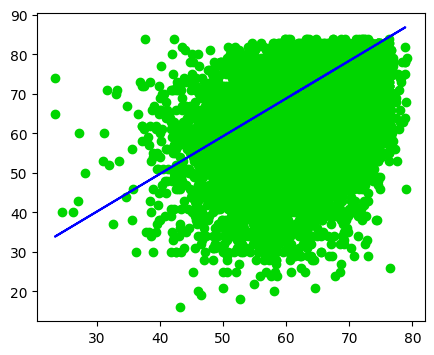

In [ ]:
#Elaboración de diagramas de dispersión, reconocer variables explicativas y no explicativas

plt.figure(figsize=(5,4)) #Genera el tamaño de la figura
plt.scatter(tabla_regresion1["ESTU_INSE_INDIVIDUAL"],tabla_regresion1["PUNT_MATEMATICAS"], c="#00D600") #Diagrama de dispersión, con
                                                                                                            #tabla_regresion1["PUNT_LECTURA_CRITICA"] → valores del eje X (variable explicativa)
                                                                                                            #tabla_regresion1["ESTU_INSE_INDIVIDUAL"] → valores del eje Y (variable respuesta)

plt.plot(testx, pred_lineal0, linestyle = "-", color= "blue")
plt.show()

Mediante el diagrama de dispersión podemos observar que amedida de que el puntaje de matemáticas en la  prueba ICFES aumenta el índice socioeconómico individual muestra un comportamiento también a crecer, generando una posible dependendependencia débil de las variables de estudio ya que el índice socioeconómico no explica de manera significativa el desempeño en la prueba.

- Diagrama de Dispersión para ESTU_INSE_INDIVIDUAL y PUNT_

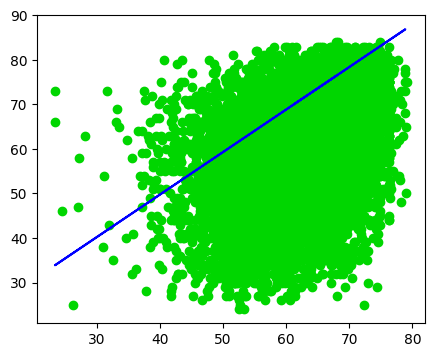

In [ ]:
#Elaboración de diagramas de dispersión, reconocer variables explicativas y no explicativas

plt.figure(figsize=(5,4)) #Genera el tamaño de la figura
plt.scatter(tabla_regresion1["ESTU_INSE_INDIVIDUAL"],tabla_regresion1["PUNT_SOCIALES_CIUDADANAS"], c="#00D600") #Diagrama de dispersión, con
                                                                                                            #tabla_regresion1["PUNT_LECTURA_CRITICA"] → valores del eje X (variable explicativa)
                                                                                                            #tabla_regresion1["ESTU_INSE_INDIVIDUAL"] → valores del eje Y (variable respuesta)

plt.plot(testx, pred_lineal0, linestyle = "-", color= "blue")
plt.show()

Mediante el diagrama de dispersión podemos observar que amedida de que el puntaje de matemáticas en la  prueba ICFES aumenta el índice socioeconómico individual muestra un comportamiento también a crecer, generando una posible dependendependencia débil de las variables de estudio ya que el índice socioeconómico no explica de manera significativa el desempeño en la prueba.

- Diagrama de Dispersión para ESTU_INSE_INDIVIDUAL y PUNT_INGLES


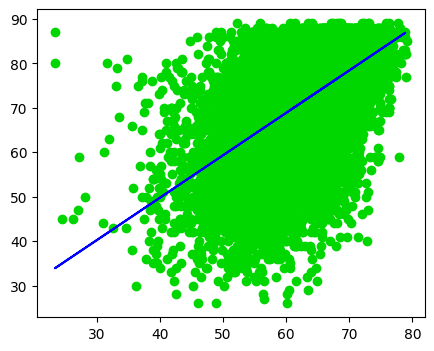

In [ ]:
#Elaboración de diagramas de dispersión, reconocer variables explicativas y no explicativas

plt.figure(figsize=(5,4)) #Genera el tamaño de la figura
plt.scatter(tabla_regresion1["ESTU_INSE_INDIVIDUAL"],tabla_regresion1["PUNT_INGLES"], c="#00D600") #Diagrama de dispersión, con
                                                                                                            #tabla_regresion1["PUNT_LECTURA_CRITICA"] → valores del eje X (variable explicativa)
                                                                                                            #tabla_regresion1["ESTU_INSE_INDIVIDUAL"] → valores del eje Y (variable respuesta)

plt.plot(testx, pred_lineal0, linestyle = "-", color= "blue")
plt.show()

Mediante el diagrama de dispersión podemos observar que amedida de que el puntaje de matemáticas en la  prueba ICFES aumenta el índice socioeconómico individual muestra un comportamiento también a crecer, generando una posible dependendependencia débil de las variables de estudio ya que el índice socioeconómico no explica de manera significativa el desempeño en la prueba.

# Coeficientes de Correlación

In [ ]:
#Puntaje Matemáticas vs Ciencias Naturales
pearson = np.corrcoef(tabla_regresion1['PUNT_MATEMATICAS'], tabla_regresion1['PUNT_C_NATURALES'])[0,1]
spearman, _ = spearmanr(tabla_regresion1['PUNT_MATEMATICAS'], tabla_regresion1['PUNT_C_NATURALES'])
kendall, _ = kendalltau(tabla_regresion1['PUNT_MATEMATICAS'], tabla_regresion1['PUNT_C_NATURALES'])
df_resultados = pd.DataFrame({
    'Tipo de Coeficiente': ['Pearson', 'Spearman', 'Kendall'],
    'Valor': [pearson, spearman, kendall]
})
print("\n Coeficientes de Correlación Matemáticas vs Ciencias Naturales")
print(df_resultados.to_string(index=False))


 Coeficientes de Correlación Matemáticas vs Ciencias Naturales
Tipo de Coeficiente    Valor
            Pearson 0.794614
           Spearman 0.801006
            Kendall 0.620175


In [ ]:
#Puntaje Inglés vs Ciencias Naturales
pearson = np.corrcoef(tabla_regresion1['PUNT_C_NATURALES'], tabla_regresion1['PUNT_INGLES'])[0,1]
spearman, _ = spearmanr(tabla_regresion1['PUNT_C_NATURALES'], tabla_regresion1['PUNT_INGLES'])
kendall, _ = kendalltau(tabla_regresion1['PUNT_C_NATURALES'], tabla_regresion1['PUNT_INGLES'])
df_resultados = pd.DataFrame({
    'Tipo de Coeficiente': ['Pearson', 'Spearman', 'Kendall'],
    'Valor': [pearson, spearman, kendall]
})
print("\n Coeficientes de Correlación Inglés vs Ciencias Naturales")
print(df_resultados.to_string(index=False))


 Coeficientes de Correlación Inglés vs Ciencias Naturales
Tipo de Coeficiente    Valor
            Pearson 0.621238
           Spearman 0.601058
            Kendall 0.436750


In [ ]:
#Puntaje Ciencias Naturales vs Lectura Crítica
pearson = np.corrcoef(tabla_regresion1['PUNT_C_NATURALES'], tabla_regresion1['PUNT_LECTURA_CRITICA'])[0,1]
spearman, _ = spearmanr(tabla_regresion1['PUNT_C_NATURALES'], tabla_regresion1['PUNT_LECTURA_CRITICA'])
kendall, _ = kendalltau(tabla_regresion1['PUNT_C_NATURALES'], tabla_regresion1['PUNT_LECTURA_CRITICA'])
df_resultados = pd.DataFrame({
    'Tipo de Coeficiente': ['Pearson', 'Spearman', 'Kendall'],
    'Valor': [pearson, spearman, kendall]
})
print("\n Coeficientes de Correlación Ciencias Naturales vs Lectura Crítica")
print(df_resultados.to_string(index=False))


 Coeficientes de Correlación Ciencias Naturales vs Lectura Crítica
Tipo de Coeficiente    Valor
            Pearson 0.733915
           Spearman 0.727555
            Kendall 0.549636


In [ ]:
#Puntaje Sociales y Ciudadanas vs Ciencias Naturales
pearson = np.corrcoef(tabla_regresion1['PUNT_SOCIALES_CIUDADANAS'], tabla_regresion1['PUNT_C_NATURALES'])[0,1]
spearman, _ = spearmanr(tabla_regresion1['PUNT_SOCIALES_CIUDADANAS'], tabla_regresion1['PUNT_C_NATURALES'])
kendall, _ = kendalltau(tabla_regresion1['PUNT_SOCIALES_CIUDADANAS'], tabla_regresion1['PUNT_C_NATURALES'])
df_resultados = pd.DataFrame({
    'Tipo de Coeficiente': ['Pearson', 'Spearman', 'Kendall'],
    'Valor': [pearson, spearman, kendall]
})
print("\n Coeficientes de Correlación Sociales y Ciudadanas vs Ciencias Naturales")
print(df_resultados.to_string(index=False))


 Coeficientes de Correlación Sociales y Ciudadanas vs Ciencias Naturales
Tipo de Coeficiente    Valor
            Pearson 0.781858
           Spearman 0.776094
            Kendall 0.594792


- Como los coeficientes de Pearson y Spearman en cada unos de los pares analizados son muy similares o cercanos nos indica que la relación entre los puntajes no solo es fuerte y positiva, sino que se ajusta muy bien a un modelo lineal además demuestra que no hay una distorsión extrema o sesgos drásticos en la tendencia central.
- Para kendall tenemos que siempre es menor tanto al de Spearman como al de Pearson lo cual es normal ya que es más riguroso


Recta de Regresión

In [39]:
modelo_lineal = LinearRegression() #Carga de función lineal
regresion = modelo_lineal.fit(trainX,trainY) #Reconocimiento de variable respuesta y explicativas (Datos de entrenamiento)
pred_lineal = regresion.predict(testX)  #Predicción datos de validación

#Recta de regresión

#MODELO DE REGERESIÓN LINEAL MULTIPLE
- **Datos de entrenamiento:** Datos con los cuales se entrena el modelo son aquellos con los que se estiman los parámetros

```
Diagrama de dispersión, con variable respuesta
'ESTU_INSE_INDIVIDUAL' y con todas las variables explicativas
'PUNT_LECTURA_CRITICA', 'PUNT_MATEMATICAS', 'PUNT_C_NATURALES',
'PUNT_SOCIALES_CIUDADANAS' y 'PUNT_INGLES'

```
ESTU_INSE_INDIVIDUAL = a1 PUNT_LECTURA_CRITICA + a2 PUNT_MATEMATICAS + a3 PUNT_C_NATURALES + a4 PUNT_SOCIALES_CIUDADANAS + a5 PUNT_INGLES + b + E

E ~ Normal (0, sigma^2)

Generalmente se toman 80% de los datos para de entrenamiento y 20% de validación.

Calculo de las esperanzas

- **Datos de validación:** Son los datos con los cuales se determina si el modelo implementado tiene un buen ajuste o no.

In [40]:
X = tabla_regresion1.drop("ESTU_INSE_INDIVIDUAL", axis = 1) #Eliminación de la columna correspondiente a la variable respuesta
Y = tabla_regresion1["ESTU_INSE_INDIVIDUAL"] #Define la variable respuesta.
trainX, testX, trainY, testY = train_test_split(X, Y, test_size= 0.2, random_state= 0)  #Identifica datos de entrenamiento y validación
                                                                                        #Tamaño de los datos de validación corresponde a 20%
trainX.head(4) #Visualizar los primeros datos de entrenamiento

,PUNT_LECTURA_CRITICA,PUNT_MATEMATICAS,PUNT_C_NATURALES,PUNT_SOCIALES_CIUDADANAS,PUNT_INGLES
12545,46,58,55,42,68.0
10887,69,55,58,63,82.0
6215,54,64,56,50,69.0
5182,68,74,62,59,88.0


#Coeficiente de Determinación

In [41]:
#Calculo de coeficiente de determinación para datos de validación
r2_lineal = regresion.score(testX, testY)
r2_lineal

0.2962348737142402

Determinar el coeficiente de determinación con la particularidad de ir eliminando variables de los datos de entrenamiento (Probar con cada uno).

------
##"PUNT_LECT_CRITICA"


In [42]:
X1 = tabla_regresion1[['PUNT_MATEMATICAS','PUNT_C_NATURALES','PUNT_SOCIALES_CIUDADANAS','PUNT_INGLES']] #Eliminación de la columna correspondiente a la variable respuesta
Y1 = tabla_regresion1["ESTU_INSE_INDIVIDUAL"] #Define la variable respuesta.
train1X, test1X, train1Y, test1Y = train_test_split(X1, Y1, test_size= 0.2, random_state= 0)  #Identifica datos de entrenamiento y validación
                                                                                        #Tamaño de los datos de validación corresponde a 20%
train1X.head(4) #Visualizar los primeros datos de entrenamiento

,PUNT_MATEMATICAS,PUNT_C_NATURALES,PUNT_SOCIALES_CIUDADANAS,PUNT_INGLES
12545,58,55,42,68.0
10887,55,58,63,82.0
6215,64,56,50,69.0
5182,74,62,59,88.0


In [43]:
modelo_lineal1 = LinearRegression() #Carga de función lineal
regresion1 = modelo_lineal.fit(train1X,train1Y) #Reconocimiento de variable respuesta y explicativas (Datos de entrenamiento)
pred_lineal1 = regresion1.predict(test1X)  #Predicción datos de validación
r2_lineal1 = regresion.score(test1X, test1Y)#Calculo de coeficiente de determinación para datos de validación
r2_lineal1

0.2947540211982348

Comparando el coeficiente de determinación sin tomar como variable explicativa 'PUNT_LECTURA_CRITICA' y tomando el coeficiente de determinación con 'PUNT_LECTURA_CRITICA' se observa que el coeficiente de determinación con 'PUNT_LECTURA_CRITICA' es de 0.2962348737142402, además se observa que el coeficiente de determinación sin 'PUNT_LECTURA_CRITICA' es de 0.2947540211982348, quiere decir que 'PUNT_LECTURA_CRITICA' es explicativa.

-----

---

## 'PUNT_MATEMATICAS'

In [44]:
X2 = tabla_regresion1[['PUNT_LECTURA_CRITICA' ,'PUNT_C_NATURALES','PUNT_SOCIALES_CIUDADANAS','PUNT_INGLES']] #Eliminación de la columna correspondiente a la variable respuesta
Y2 = tabla_regresion1["ESTU_INSE_INDIVIDUAL"] #Define la variable respuesta.
train2X, test2X, train2Y, test2Y = train_test_split(X2, Y2, test_size= 0.2, random_state= 0)  #Identifica datos de entrenamiento y validación
                                                                                        #Tamaño de los datos de validación corresponde a 20%
train2X.head(4) #Visualizar los primeros datos de entrenamiento

,PUNT_LECTURA_CRITICA,PUNT_C_NATURALES,PUNT_SOCIALES_CIUDADANAS,PUNT_INGLES
12545,46,55,42,68.0
10887,69,58,63,82.0
6215,54,56,50,69.0
5182,68,62,59,88.0


In [45]:
modelo_lineal2 = LinearRegression() #Carga de función lineal
regresion2 = modelo_lineal.fit(train2X,train2Y) #Reconocimiento de variable respuesta y explicativas (Datos de entrenamiento)
pred_lineal2 = regresion2.predict(test2X)  #Predicción datos de validación
r2_lineal2 = regresion.score(test2X, test2Y)#Calculo de coeficiente de determinación para datos de validación
r2_lineal2

0.29483912553842895

Comparando el coeficiente de determinación sin tomar como variable explicativa 'PUNT_LECTURA_CRITICA' y tomando el coeficiente de determinación con 'PUNT_LECTURA_CRITICA' se observa que el coeficiente de determinación con 'PUNT_LECTURA_CRITICA' es de 0.2962348737142402, además se observa que el coeficiente de determinación sin 'PUNT_LECTURA_CRITICA' es de 0.2947540211982348, quiere decir que 'PUNT_LECTURA_CRITICA' es explicativa.

-----

---
##'PUNT_C_NATURALES'

In [46]:
X3 = tabla_regresion1[['PUNT_LECTURA_CRITICA','PUNT_MATEMATICAS','PUNT_SOCIALES_CIUDADANAS','PUNT_INGLES']] #Eliminación de la columna correspondiente a la variable respuesta
Y3 = tabla_regresion1["ESTU_INSE_INDIVIDUAL"] #Define la variable respuesta.
train3X, test3X, train3Y, test3Y = train_test_split(X3, Y3, test_size= 0.2, random_state= 0)  #Identifica datos de entrenamiento y validación
                                                                                        #Tamaño de los datos de validación corresponde a 20%
train3X.head(4) #Visualizar los primeros datos de entrenamiento

,PUNT_LECTURA_CRITICA,PUNT_MATEMATICAS,PUNT_SOCIALES_CIUDADANAS,PUNT_INGLES
12545,46,58,42,68.0
10887,69,55,63,82.0
6215,54,64,50,69.0
5182,68,74,59,88.0


In [47]:
modelo_lineal3 = LinearRegression() #Carga de función lineal
regresion3 = modelo_lineal.fit(train3X,train3Y) #Reconocimiento de variable respuesta y explicativas (Datos de entrenamiento)
pred_lineal3 = regresion3.predict(test3X)  #Predicción datos de validación
r2_lineal3 = regresion.score(test3X, test3Y)#Calculo de coeficiente de determinación para datos de validación
r2_lineal3

0.2959371782929858

Comparando el coeficiente de determinación sin tomar como variable explicativa 'PUNT_C_NATURALES' y tomando el coeficiente de determinación con 'PUNT_C_NATURALES' se observa que el coeficiente de determinación con 'PUNT_C_NATURALES' es de 0.2962348737142402, además se observa que el coeficiente de determinación sin 'PUNT_C_NATURALES' es de 0.2959371782929858, quiere decir que 'PUNT_C_NATURALES' es explicativa.

----

---

## 'PUNT_SOCIALES_CIUDADANAS'

In [48]:
X4 = tabla_regresion1[['PUNT_LECTURA_CRITICA','PUNT_MATEMATICAS','PUNT_C_NATURALES','PUNT_INGLES']] #Eliminación de la columna correspondiente a la variable respuesta
Y4 = tabla_regresion1["ESTU_INSE_INDIVIDUAL"] #Define la variable respuesta.
train4X, test4X, train4Y, test4Y = train_test_split(X4, Y4, test_size= 0.2, random_state= 0)  #Identifica datos de entrenamiento y validación
                                                                                        #Tamaño de los datos de validación corresponde a 20%
train4X.head(4) #Visualizar los primeros datos de entrenamiento

,PUNT_LECTURA_CRITICA,PUNT_MATEMATICAS,PUNT_C_NATURALES,PUNT_INGLES
12545,46,58,55,68.0
10887,69,55,58,82.0
6215,54,64,56,69.0
5182,68,74,62,88.0


In [49]:
modelo_lineal4 = LinearRegression() #Carga de función lineal
regresion4 = modelo_lineal.fit(train4X,train4Y) #Reconocimiento de variable respuesta y explicativas (Datos de entrenamiento)
pred_lineal4 = regresion4.predict(test4X)  #Predicción datos de validación
r2_lineal4 = regresion.score(test4X, test4Y)#Calculo de coeficiente de determinación para datos de validación
r2_lineal4

0.2961694957558495

**Análisis**<br>
Comparando el coeficiente de determinación sin tomar como variable explicativa 'PUNT_SOCIALES_CIUDADANAS' y tomando el coeficiente de determinación con 'PUNT_SOCIALES_CIUDADANAS' se observa que el coeficiente de determinación con 'PUNT_SOCIALES_CIUDADANAS' es de 0.2962348737142402, además se observa que el coeficiente de determinación sin 'PUNT_SOCIALES_CIUDADANAS' es de 0.2961694957558495.
Dado que la diferencia es mínima, se concluye que 'PUNT_SOCIALES_CIUDADANAS' no es una variable explicativa, ya que su aporte al modelo es prácticamente nulo.

----

---

##'PUNT_INGLES'

In [50]:
X5 = tabla_regresion1[['PUNT_LECTURA_CRITICA','PUNT_MATEMATICAS','PUNT_SOCIALES_CIUDADANAS','PUNT_C_NATURALES']] #Eliminación de la columna correspondiente a la variable respuesta
Y5 = tabla_regresion1["ESTU_INSE_INDIVIDUAL"] #Define la variable respuesta.
train5X, test5X, train5Y, test5Y = train_test_split(X5, Y5, test_size= 0.2, random_state= 0)  #Identifica datos de entrenamiento y validación
                                                                                        #Tamaño de los datos de validación corresponde a 20%
train5X.head(4) #Visualizar los primeros datos de entrenamiento

,PUNT_LECTURA_CRITICA,PUNT_MATEMATICAS,PUNT_SOCIALES_CIUDADANAS,PUNT_C_NATURALES
12545,46,58,42,55
10887,69,55,63,58
6215,54,64,50,56
5182,68,74,59,62


In [51]:
modelo_lineal5 = LinearRegression() #Carga de función lineal
regresion5 = modelo_lineal.fit(train5X,train5Y) #Reconocimiento de variable respuesta y explicativas (Datos de entrenamiento)
pred_lineal5 = regresion5.predict(test5X)  #Predicción datos de validación
r2_lineal5 = regresion.score(test5X, test5Y)#Calculo de coeficiente de determinación para datos de validación
r2_lineal5

0.13362998486245814

Comparando el coeficiente de determinación sin tomar como variable explicativa 'PUNT_INGLES' y tomando el coeficiente de determinación con 'PUNT_INGLES' se observa que el coeficiente de determinación con 'PUNT_INGLES' es de 0.2962348737142402, además se observa que el coeficiente de determinación sin 'PUNT_INGLES' es de 0.13362998486245814, Se evidencia una disminución significativa, por lo que se concluye que 'PUNT_INGLES' es la variable más explicativa del modelo. En conclusión, la variable 'PUNT_INGLES' es la más influyente en el modelo, le sigue 'PUNT_LECTURA_CRITICA' y las  demás representan similitud mientras que 'PUNT_SOCIALES_CIUDADANAS' no aporta significativamente a la explicación de la variable respuesta.

# Diagrama con el plano de dispersión

In [52]:
XY, Z = tabla_regresion1[['PUNT_INGLES', 'PUNT_LECTURA_CRITICA']], tabla_regresion1['ESTU_INSE_INDIVIDUAL'] #Eliminación de la columna correspondiente a la variable respuesta
trainXY, testXY, trainZ, testZ = train_test_split(XY, Z, test_size=0.2, random_state=0) #Identifica datos de entrenamiento y validación
                                                                                      #Tamaño de los datos de validación corresponde a 20%
trainXY.head(4)                      #Visualizar los primeros datos de entrenamiento

,PUNT_INGLES,PUNT_LECTURA_CRITICA
12545,68.0,46
10887,82.0,69
6215,69.0,54
5182,88.0,68


In [53]:
#Implementación de modelo de regresión lineal múltiple
modelo1 = LinearRegression()
modelo1.fit(trainXY, trainZ) #Entrenamiento del modelo

LinearRegression()

In [54]:
#Predicción del modelo
modelo1.score(testXY, testZ)

0.29529055571088336

Comparado con r2_lineal (0.2962348737142402) observamos que no cambia mucho su valor a pesar de usar sólo dos variables (Uso de las más explicativas)

In [56]:
#Determinar los coeficientes del modelo
array = modelo1.coef_ #Determinar los estimadores del modelo de regresión
array

array([ 0.33277288, -0.01765587])

*   Intercepto: 0.33277288
*   Pendiente: -0.01765587

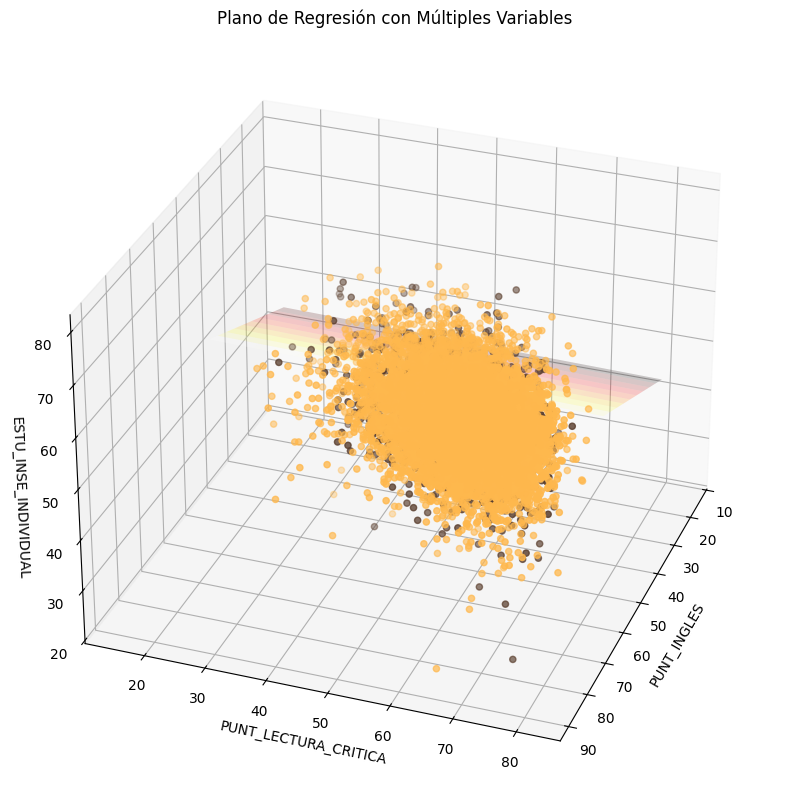

In [64]:
#Creación de malla
fig = plt.figure(figsize=(10,10))
ax = fig.add_subplot(111, projection='3d')
xx, yy = np.meshgrid(np.linspace(15, 50, num=10), np.linspace(15, 80, num=10))
plano_reg = array[0]*xx + array[1]*yy + modelo1.intercept_   #Regresión lineal múltiple con los parámetros estimados

#Dibujar la superficie del plano de regresión
ax.plot_surface(xx, yy, plano_reg, alpha= 0.2, cmap='hot')

#Puntos de los datos de entrenamiento
ax.scatter(trainXY['PUNT_INGLES'], trainXY['PUNT_LECTURA_CRITICA'], trainZ, c='#FFB84D', s=20) ##Color naranja pero le bajamos intensidad

#Puntos de los datos de validación
ax.scatter(testXY['PUNT_INGLES'], testXY['PUNT_LECTURA_CRITICA'], testZ, c='#5A3E2D', s=20)

#Visualización del gráfico
ax.view_init(elev=30, azim=20)

#Nombre de ejes
ax.set_xlabel('PUNT_INGLES')
ax.set_ylabel('PUNT_LECTURA_CRITICA')
ax.set_zlabel('ESTU_INSE_INDIVIDUAL')
ax.set_title('Plano de Regresión con Múltiples Variables')
plt.show()

Como el coeficiente de determinación nos dio aproximadamente 29% debemos recordar que para tener un buen coeficiente de determinación debe ser superior al 80%.
Hacemos uso de una red neuronal multicapa.
##Entrenamiento del modelo

In [65]:
mlp_reg = MLPRegressor(hidden_layer_sizes=(10, 10, 10, 10, 10, 10, 10, 10, 10, 10),
                       max_iter=500, activation= 'relu',
                       solver= 'adam', learning_rate= 'invscaling') #10 capitas de diez nodos

mlp_reg.fit(trainX, trainY) #Entrenamiento del modelo

MLPRegressor(hidden_layer_sizes=(10, 10, 10, 10, 10, 10, 10, 10, 10, 10),
             learning_rate='invscaling', max_iter=500)

In [66]:
#Determinar el coeficiente de correlación
mlp_reg.score(testX, testY)

0.27389766952225647

No ofrece un mejor ajuste, se espera que al agregar muchas más capas pueda ofrecer un modelo con mayor ajuste.
Para hacer una predicción de los valores no observados, se determina un valor al cual se le quiera hacer la predicción.

In [67]:
X.head(4) #Visualización de los primeros 4 datos de la variable X

,PUNT_LECTURA_CRITICA,PUNT_MATEMATICAS,PUNT_C_NATURALES,PUNT_SOCIALES_CIUDADANAS,PUNT_INGLES
3,45,41,41,27,58.0
4,53,55,41,56,69.0
5,63,38,60,59,45.0
6,69,60,59,51,50.0


#Diagrama de Dispersión lineal Multiple

In [68]:
# =============================================================================
# MODELO DE REGRESIÓN LINEAL MÚLTIPLE (con las 5 variables explicativas)
# =============================================================================

# Variables explicativas (las 5 puntajes)
X = icfes_sin_nan[['PUNT_LECTURA_CRITICA',
                    'PUNT_MATEMATICAS',
                    'PUNT_C_NATURALES',
                    'PUNT_SOCIALES_CIUDADANAS',
                    'PUNT_INGLES']]

# Variable respuesta
Y = icfes_sin_nan['ESTU_INSE_INDIVIDUAL']

# División 80% entrenamiento, 20% prueba
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

# Crear y entrenar el modelo
modelo_lineal_multiple = LinearRegression()
modelo_lineal_multiple.fit(X_train, y_train)

# Mostrar resultados
print("=== MODELO DE REGRESIÓN LINEAL MÚLTIPLE ===")
print(f"Intercepto: {modelo_lineal_multiple.intercept_:.4f}")
print("\nCoeficientes:")
for var, coef in zip(X.columns, modelo_lineal_multiple.coef_):
    print(f"  {var}: {coef:.4f}")

=== MODELO DE REGRESIÓN LINEAL MÚLTIPLE ===
Intercepto: 41.6184

Coeficientes:
  PUNT_LECTURA_CRITICA: -0.0305
  PUNT_MATEMATICAS: 0.0459
  PUNT_C_NATURALES: -0.0058
  PUNT_SOCIALES_CIUDADANAS: 0.0056
  PUNT_INGLES: 0.2801


El coeficiente de mayor magnitud es el de **PUNT_INGLES (0.2801)**, lo que indica que el puntaje de inglés es la variable con mayor influencia positiva sobre el índice socioeconómico individual. Las demás variables presentan coeficientes cercanos a cero, lo que sugiere que su aporte al modelo es mínimo.

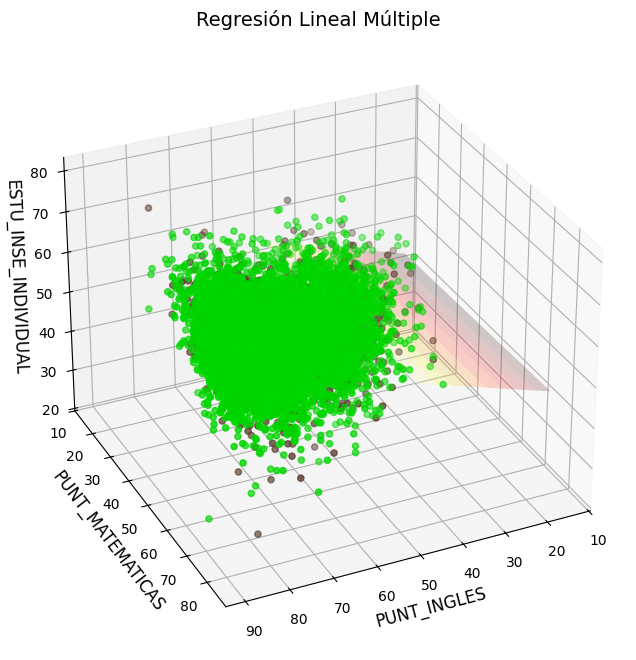

In [73]:
#  Seleccionar variables explicativas, se escogieron las dos con coef positivos para hacer el grafico, pero
# este se puede hacer con cualesquiera 2 variaples explicativas(las que irán en X e Y del plano)
#    y la variable respuesta (Z)
XY = tabla_regresion1[['PUNT_INGLES', 'PUNT_MATEMATICAS']]
Z = tabla_regresion1['ESTU_INSE_INDIVIDUAL']

# Dividir en entrenamiento (80%) y prueba (20%)
trainXY, testXY, trainZ, testZ = train_test_split(XY, Z, test_size=0.2, random_state=0)

# Crear y entrenar el modelo de regresión lineal con las dos variables explicativas
modelo_3d = LinearRegression()
modelo_3d.fit(trainXY, trainZ)

# Obtener los coeficientes (pendientes para cada eje X e Y)
coefs = modelo_3d.coef_  # array con [coef_ingles, coef_matematicas]
intercept = modelo_3d.intercept_

# Crear la malla para el plano
xx, yy = np.meshgrid(
    np.linspace(15, 50, num=10),   # rango de PUNT_INGLES (mínimo y máximo aproximado)
    np.linspace(15, 80, num=10)    # rango de PUNT_MATEMATICAS
)
# Ecuación del plano: Z = coef_ingles * X + coef_matematicas * Y + intercept
plano = coefs[0] * xx + coefs[1] * yy + intercept

# Crear la figura
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Dibujar el plano de regresión (superficie)
ax.plot_surface(xx, yy, plano, alpha=0.2, cmap='hot')

# Dibujar puntos de entrenamiento (azul)
ax.scatter(trainXY['PUNT_INGLES'], trainXY['PUNT_MATEMATICAS'], trainZ,
           c='#00D600', s=20, label='Entrenamiento')

# Dibujar puntos de prueba (morado)
ax.scatter(testXY['PUNT_INGLES'], testXY['PUNT_MATEMATICAS'], testZ,
           c='#5A3E2D', s=20, label='Prueba')

# Configurar ángulo de vista
ax.view_init(elev=30, azim=65)

# Etiquetas de los ejes
ax.set_xlabel('PUNT_INGLES', fontsize=12)
ax.set_ylabel('PUNT_MATEMATICAS', fontsize=12)
ax.set_zlabel('ESTU_INSE_INDIVIDUAL', fontsize=12)
ax.set_title('Regresión Lineal Múltiple', fontsize=14)

# Mostrar gráfico
plt.show()

#Modelo de Red Neuronal